# LLM-as-a-Judge Analysis

This notebook uses an LLM (Minimax M2) to evaluate the quality of SQL queries generated by each model.

**Judge Model:** minimax/minimax-m2

**Evaluation Criteria:**
1. **Correctness (50%)**: Does it answer the question correctly?
2. **Completeness (35%)**: Does it retrieve all necessary data?
3. **Efficiency (15%)**: Is the query well-optimized?

**Models evaluated:**
- ollama-duckdb-nsql
- ollama-llama2
- ollama-phi3
- openrouter-gemini-2.5-flash
- openrouter-gpt-5-mini
- openrouter-gpt-oss-120b
- openrouter-qwen3-32b

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from openai import OpenAI
from dotenv import load_dotenv
import os
from typing import Dict, Any
import time

# Set style (same as previous notebooks)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Color palette (same as previous notebooks)
MODEL_COLORS = {
    'ollama-duckdb-nsql': '#2E86AB',
    'ollama-llama2': '#A23B72',
    'ollama-phi3': '#F18F01',
    'openrouter-gemini-2.5-flash': '#C73E1D',
    'openrouter-gpt-5-mini': '#6A994E',
    'openrouter-gpt-oss-120b': '#BC4B51',
    'openrouter-qwen3-32b': '#8B5A3C'
}

# Paths
BASE_PATH = Path('../..')
RESULTS_PATH = BASE_PATH / 'backend' / 'logs' / 'batch-results'
TEST_SUITE_PATH = BASE_PATH / 'backend' / 'tests' / 'test-suite.json'
FIGS_PATH = BASE_PATH / 'analysis' / 'figs'
TABLES_PATH = BASE_PATH / 'analysis' / 'tables'

# Load environment variables
env_path = BASE_PATH / '.env'
load_dotenv(env_path)

print("✓ Libraries imported and paths configured")

✓ Libraries imported and paths configured


## 2. Load Test Data

In [2]:
# Load test suite
with open(TEST_SUITE_PATH, 'r', encoding='utf-8') as f:
    test_suite = json.load(f)

# Create mappings
test_questions = {}
for q in test_suite['questions']:
    test_questions[q['id']] = {
        'question': q['question'],
        'expectedSQL': q['expectedSQL'],
        'description': q['description'],
        'complexity': q['complexity'],
        'category': q['category'],
        'expectedResults': q['expectedResults']
    }

print(f"✓ Loaded test suite with {len(test_questions)} questions")

# Load all model results
def load_model_results(model_name):
    model_path = RESULTS_PATH / model_name
    results = []
    
    for i in range(1, 21):
        query_file = model_path / f'query-{i}.json'
        if query_file.exists():
            with open(query_file, 'r', encoding='utf-8') as f:
                data = json.load(f)
                results.append(data)
    
    return results

models = list(MODEL_COLORS.keys())
all_results = {}

for model in models:
    all_results[model] = load_model_results(model)
    print(f"✓ Loaded {len(all_results[model])} queries for {model}")

✓ Loaded test suite with 20 questions
✓ Loaded 20 queries for ollama-duckdb-nsql
✓ Loaded 20 queries for ollama-llama2
✓ Loaded 20 queries for ollama-phi3
✓ Loaded 20 queries for openrouter-gemini-2.5-flash
✓ Loaded 20 queries for openrouter-gpt-5-mini
✓ Loaded 20 queries for openrouter-gpt-oss-120b
✓ Loaded 20 queries for openrouter-qwen3-32b


## 3. Define Evaluation Schema and Function

In [3]:
SYSTEM_PROMPT = """
You are an expert SQL evaluator. You will receive: 
- the natural language question
- the expected SQL
- the generated SQL
- expected vs actual result metadata
Evaluate the generated SQL strictly following the scoring rubric.

Use ONLY the following DATABASE SCHEMA for all reasoning:

TABLE: categories
  Columns:
    - category_id (int, PK)
    - name (varchar)
    - description (text)
    - created_at (timestamp)
  Indexes:
    - categories_name_key
    - categories_pkey

TABLE: customers
  Columns:
    - customer_id (int, PK)
    - name (varchar)
    - email (varchar)
    - phone (varchar)
    - birth_date (date)
    - address (text)
    - city (varchar)
    - country (varchar)
    - registration_date (date)
    - is_active (bool)
  Indexes:
    - customers_email_key
    - customers_pkey
    - idx_customers_active

TABLE: orders
  Columns:
    - order_id (int, PK)
    - customer_id (FK -> customers)
    - order_date (timestamp)
    - total_amount (numeric)
    - status (varchar)
    - payment_method (varchar)
    - shipped_date (timestamp)
    - delivered_date (timestamp)
  Indexes:
    - idx_orders_customer
    - idx_orders_date
    - idx_orders_status_date
    - orders_pkey

TABLE: order_items
  Columns:
    - order_item_id (int, PK)
    - order_id (FK -> orders)
    - product_id (FK -> products)
    - quantity (int)
    - unit_price (numeric)
    - discount (numeric)
  Indexes:
    - idx_order_items_order
    - idx_order_items_product
    - order_items_pkey

TABLE: products
  Columns:
    - product_id (int, PK)
    - name (varchar)
    - description (text)
    - price (numeric)
    - stock_quantity (int)
    - category_id (FK -> categories)
    - supplier_id (FK -> suppliers)
    - created_at (timestamp)
    - is_available (bool)
  Indexes:
    - idx_products_available
    - idx_products_category
    - idx_products_category_price      
    - idx_products_supplier
    - products_pkey

TABLE: reviews
  Columns:
    - review_id (int, PK)
    - product_id (FK -> products)
    - customer_id (FK -> customers)
    - rating (int)
    - comment (text)
    - review_date (timestamp)
  Indexes:
    - idx_reviews_customer
    - idx_reviews_product
    - reviews_pkey

TABLE: suppliers
  Columns:
    - supplier_id (int, PK)
    - name (varchar)
    - contact_name (varchar)
    - email (varchar)
    - phone (varchar)
    - country (varchar)
    - created_at (timestamp)
  Indexes:
    - suppliers_email_key
    - suppliers_pkey
  
RELATIONSHIPS:
  - order_items -> orders (via order_id)
  - order_items -> products (via product_id)
  - orders -> customers (via customer_id)
  - products -> categories (via category_id)
  - products -> suppliers (via supplier_id)
  - reviews -> customers (via customer_id)
  - reviews -> products (via product_id)
    
## Evaluation Criteria

Evaluate the generated query on these dimensions (0-10 scale each):

1. **Correctness** (0-10): Does it answer the question correctly?
   - Correct tables and joins
   - Correct filters and conditions
   - Correct aggregations
   - Logical soundness

2. **Completeness** (0-10): Does it retrieve all necessary data?
   - All required columns present (aliases acceptable)
   - Row count matches or is justified
   - No missing information

3. **Efficiency** (0-10): Is the query well-optimized?
   - Appropriate use of indexes (implicit)
   - No unnecessary joins
   - Efficient filtering
   - Proper use of aggregations  

## Scoring Guidelines
- **10**: Perfect - meets all criteria flawlessly
- **8-9**: Excellent - minor improvements possible
- **6-7**: Good - functional but has notable issues
- **4-5**: Fair - works but has significant problems
- **2-3**: Poor - major issues, barely functional
- **0-1**: Failed - incorrect or non-functional

SCORING RUBRIC:
Return ONLY JSON:
{
  "correctness": number 0-10,
  "completeness": number 0-10,
  "efficiency": number 0-10,
  "overall_score": number 0-10
}

overall_score = correctness*0.5 + completeness*0.35 + efficiency*0.15
Always follow the rubric exactly.
"""


In [4]:
def build_prompt(question, expected_sql, generated_sql,
                 expected_cols, expected_rows,
                 actual_cols, actual_rows):
    return f"""
Question: {question}

Expected SQL:
{expected_sql}

Generated SQL:
{generated_sql}

Expected Results:
Columns: {expected_cols}
Rows: {expected_rows}

Actual Results:
Columns: {actual_cols}
Rows: {actual_rows}

Return ONLY the JSON scores.
"""


## 4. Evaluate Queries with Judge LLM

In [5]:
import asyncio
from openai import AsyncOpenAI
import os

client = AsyncOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=os.getenv("OPENROUTER_API_KEY")
)

JUDGE_MODEL = "x-ai/grok-code-fast-1"
CONCURRENCY = 10   # simultâneas seguras

In [6]:
async def judge_single(prompt):
    try:
        response = await client.chat.completions.create(
            model=JUDGE_MODEL,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": prompt}
            ],
            response_format={
                "type": "json_schema",
                "json_schema": {
                    "name": "judge_sql",
                    "strict": True,
                    "schema": {
                        "type": "object",
                        "properties": {
                            "correctness": {"type": "number"},
                            "completeness": {"type": "number"},
                            "efficiency": {"type": "number"},
                            "overall_score": {"type": "number"}
                        },
                        "required": [
                            "correctness",
                            "completeness",
                            "efficiency",
                            "overall_score"
                        ],
                        "additionalProperties": False
                    }
                }
            }
        )

        return json.loads(response.choices[0].message.content)

    except Exception as e:
        print("JUDGE ERROR:", e)
        return {
            "correctness": 0,
            "completeness": 0,
            "efficiency": 0,
            "overall_score": 0
        }

In [7]:
# Final unified list for judge evaluation
all_queries = []

for model, queries in all_results.items():
    for q in queries:
        qid = q["questionId"]
        t = test_questions[qid]

        expected_res = t["expectedResults"]
        actual_res = q.get("results", {})

        all_queries.append({
            "model": model,
            "questionId": qid,
            "complexity": t["complexity"],
            "category": t["category"],

            # inputs for LLM judge
            "question": t["question"],
            "expectedSQL": t["expectedSQL"],
            "generatedSQL": q.get("generatedSQL", ""),

            # expected results
            "expected_cols": expected_res.get("columns", []),
            "expected_rows": expected_res.get("rowCount", 0),

            # actual results
            "actual_cols": actual_res.get("columns", []),
            "actual_rows": actual_res.get("rowCount", None),

            # metadata
            "execution_success": q.get("executionSuccess", False)
        })

print(f"✓ Built final list of {len(all_queries)} query evaluations")


✓ Built final list of 140 query evaluations


In [8]:
async def run_all_evaluations(all_queries):
    semaphore = asyncio.Semaphore(CONCURRENCY)

    async def run_eval(query_data):
        async with semaphore:
            prompt = build_prompt(
                question=query_data["question"],
                expected_sql=query_data["expectedSQL"],
                generated_sql=query_data["generatedSQL"],
                expected_cols=query_data["expected_cols"],
                expected_rows=query_data["expected_rows"],
                actual_cols=query_data["actual_cols"],
                actual_rows=query_data["actual_rows"],
            )
            scores = await judge_single(prompt)
            
            # Return complete row with metadata + scores
            return {
                "model": query_data["model"],
                "questionId": query_data["questionId"],
                "complexity": query_data["complexity"],
                "category": query_data["category"],
                "execution_success": query_data["execution_success"],
                "correctness": scores["correctness"],
                "completeness": scores["completeness"],
                "efficiency": scores["efficiency"],
                "overall_score": scores["overall_score"]
            }

    print(f"Starting evaluation of {len(all_queries)} queries with {CONCURRENCY} concurrent requests...\n")
    
    tasks = [asyncio.create_task(run_eval(q)) for q in all_queries]
    results = await asyncio.gather(*tasks)
    
    print(f"\n✓ Completed {len(results)} evaluations")
    return results

In [9]:
import nest_asyncio
nest_asyncio.apply()

In [10]:
results = asyncio.run(run_all_evaluations(all_queries))

Starting evaluation of 140 queries with 10 concurrent requests...

JUDGE ERROR: Error code: 401 - {'error': {'message': 'User not found.', 'code': 401}}
JUDGE ERROR: Expecting value: line 1 column 1 (char 0)

✓ Completed 140 evaluations


In [11]:
eval_df = pd.DataFrame(results)

print("✓ eval_df criado com shape:", eval_df.shape)
eval_df.head()


✓ eval_df criado com shape: (140, 9)


,model,questionId,complexity,category,execution_success,correctness,completeness,efficiency,overall_score
0,ollama-duckdb-nsql,1,simple,filter,True,9,10,10,9.5
1,ollama-duckdb-nsql,2,simple,filter,True,0,0,0,0.0
2,ollama-duckdb-nsql,3,simple,filter,True,9,10,10,9.5
3,ollama-duckdb-nsql,4,simple,filter,True,10,10,10,10.0
4,ollama-duckdb-nsql,5,simple,filter,True,10,10,8,9.7


## 5. Overall Statistics

In [12]:
# Calculate overall statistics by model
judge_stats = eval_df.groupby('model').agg({
    'correctness': ['mean', 'std'],
    'completeness': ['mean', 'std'],
    'efficiency': ['mean', 'std'],
    'overall_score': ['mean', 'std']
}).round(2)

judge_stats.columns = ['_'.join(col).strip() for col in judge_stats.columns.values]
judge_stats = judge_stats.sort_values('overall_score_mean', ascending=False)

# Save table
judge_stats.to_csv(TABLES_PATH / 'judge_overall_stats.csv')
print("✓ Saved overall judge statistics table")

judge_stats

✓ Saved overall judge statistics table


,correctness_mean,correctness_std,completeness_mean,completeness_std,efficiency_mean,efficiency_std,overall_score_mean,overall_score_std
model,,,,,,,,
openrouter-gpt-oss-120b,8.80,1.24,9.60,0.88,9.65,0.59,9.21,0.94
openrouter-qwen3-32b,8.40,1.73,9.20,1.44,9.20,1.06,8.75,1.35
openrouter-gemini-2.5-flash,8.20,2.26,9.30,1.63,9.00,1.49,8.67,1.72
openrouter-gpt-5-mini,8.20,2.65,9.05,2.39,8.35,2.21,8.52,2.35
ollama-duckdb-nsql,5.55,4.21,5.40,4.83,6.15,4.06,5.55,4.26
ollama-phi3,2.90,3.57,2.45,4.01,3.40,3.20,2.84,3.56
ollama-llama2,2.70,3.39,1.75,3.32,3.65,3.63,2.47,3.30


## 6. Visualizations: Overall Scores

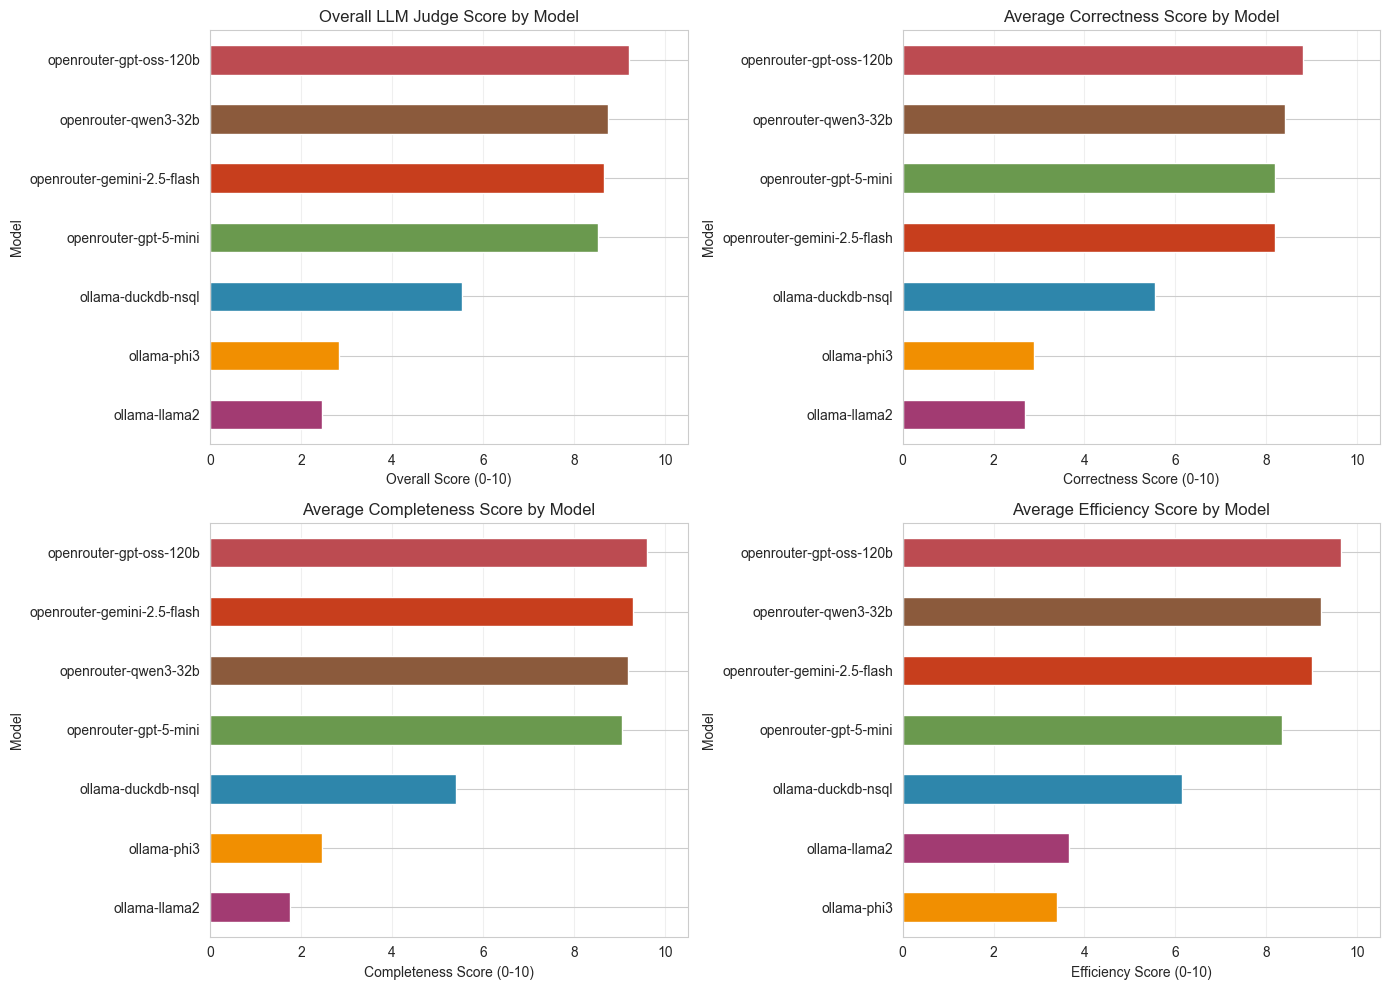

✓ Saved overall scores visualization


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall score
overall_data = eval_df.groupby('model')['overall_score'].mean().sort_values(ascending=True)
colors_overall = [MODEL_COLORS[m] for m in overall_data.index]
overall_data.plot(kind='barh', ax=axes[0, 0], color=colors_overall)
axes[0, 0].set_xlabel('Overall Score (0-10)')
axes[0, 0].set_ylabel('Model')
axes[0, 0].set_title('Overall LLM Judge Score by Model')
axes[0, 0].set_xlim(0, 10.5)
axes[0, 0].grid(axis='x', alpha=0.3)

# Correctness
correct_data = eval_df.groupby('model')['correctness'].mean().sort_values(ascending=True)
colors_correct = [MODEL_COLORS[m] for m in correct_data.index]
correct_data.plot(kind='barh', ax=axes[0, 1], color=colors_correct)
axes[0, 1].set_xlabel('Correctness Score (0-10)')
axes[0, 1].set_ylabel('Model')
axes[0, 1].set_title('Average Correctness Score by Model')
axes[0, 1].set_xlim(0, 10.5)
axes[0, 1].grid(axis='x', alpha=0.3)

# Completeness
complete_data = eval_df.groupby('model')['completeness'].mean().sort_values(ascending=True)
colors_complete = [MODEL_COLORS[m] for m in complete_data.index]
complete_data.plot(kind='barh', ax=axes[1, 0], color=colors_complete)
axes[1, 0].set_xlabel('Completeness Score (0-10)')
axes[1, 0].set_ylabel('Model')
axes[1, 0].set_title('Average Completeness Score by Model')
axes[1, 0].set_xlim(0, 10.5)
axes[1, 0].grid(axis='x', alpha=0.3)

# Efficiency
eff_data = eval_df.groupby('model')['efficiency'].mean().sort_values(ascending=True)
colors_eff = [MODEL_COLORS[m] for m in eff_data.index]
eff_data.plot(kind='barh', ax=axes[1, 1], color=colors_eff)
axes[1, 1].set_xlabel('Efficiency Score (0-10)')
axes[1, 1].set_ylabel('Model')
axes[1, 1].set_title('Average Efficiency Score by Model')
axes[1, 1].set_xlim(0, 10.5)
axes[1, 1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'judge_overall_scores.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved overall scores visualization")

## 7. Scores by Complexity

In [14]:
# Statistics by complexity
complexity_judge = eval_df.groupby(['model', 'complexity']).agg({
    'correctness': 'mean',
    'completeness': 'mean',
    'efficiency': 'mean',
    'overall_score': 'mean'
}).round(2)

complexity_judge.to_csv(TABLES_PATH / 'judge_by_complexity.csv')
print("✓ Saved complexity judge statistics table")

complexity_judge

✓ Saved complexity judge statistics table


correctness  completeness  efficiency  \
model                       complexity                                          
ollama-duckdb-nsql          complex            4.00          4.71        5.14   
                            moderate           5.62          4.38        6.12   
                            simple             7.60          8.00        7.60   
ollama-llama2               complex            0.71          0.00        1.14   
                            moderate           3.38          1.88        4.38   
                            simple             4.40          4.00        6.00   
ollama-phi3                 complex            1.14          0.43        2.29   
                            moderate           3.88          3.00        4.75   
                            simple             3.80          4.40        2.80   
openrouter-gemini-2.5-flash complex            6.86          9.29        8.57   
                            moderate           8.50          8.88        8.75   
                            simple             9.60         10.00       10.00   
openrouter-gpt-5-mini       complex            7.00          8.00        7.43   
                            moderate           8.62          9.38        8.62   
                            simple             9.20         10.00        9.20   
openrouter-gpt-oss-120b     complex            8.00          9.00        9.29   
                            moderate           9.12          9.88        9.88   
                            simple             9.40         10.00        9.80   
openrouter-qwen3-32b        complex            7.14          8.71        8.29   
                            moderate           9.50          9.62        9.62   
                            simple             8.40          9.20        9.80   

                                        overall_score  
model                       complexity                 
ollama-duckdb-nsql          complex              4.46  
                            moderate             5.13  
                            simple               7.74  
ollama-llama2               complex              0.38  
                            moderate             3.10  
                            simple               4.38  
ollama-phi3                 complex              1.22  
                            moderate             3.66  
                            simple               3.82  
openrouter-gemini-2.5-flash complex              7.96  
                            moderate             8.64  
                            simple               9.70  
openrouter-gpt-5-mini       complex              7.44  
                            moderate             8.88  
                            simple               9.47  
openrouter-gpt-oss-120b     complex              8.57  
                            moderate             9.56  
                            simple               9.55  
openrouter-qwen3-32b        complex              7.67  
                            moderate             9.59  
                            simple               8.90

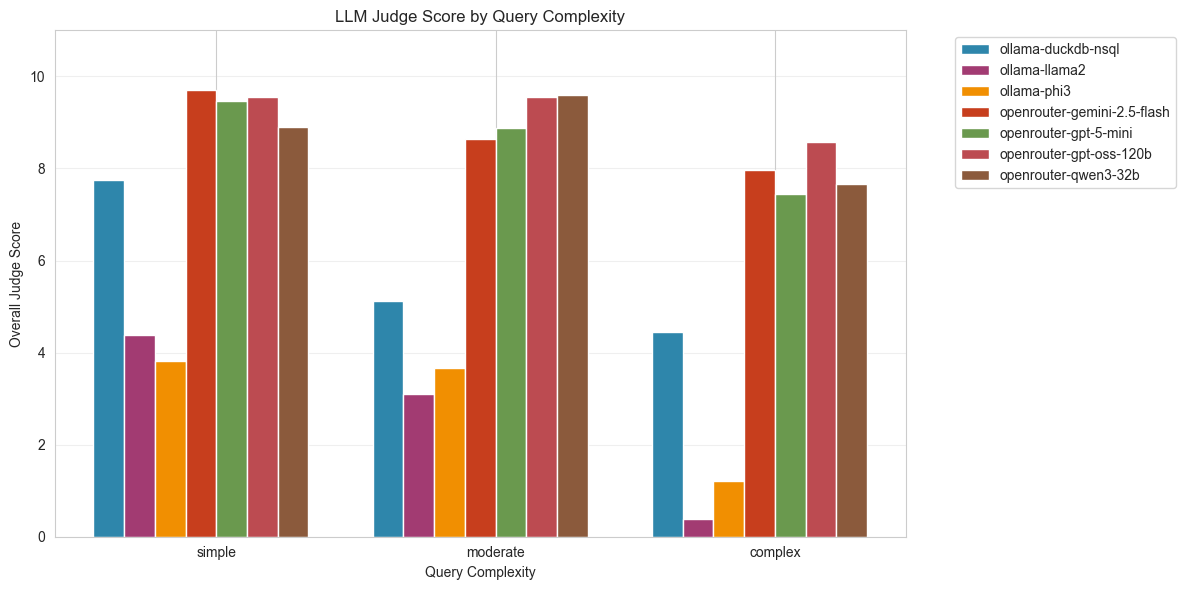

✓ Saved judge scores by complexity visualization


In [15]:
# Visualize overall score by complexity
complexity_order = ['simple', 'moderate', 'complex']
pivot_data = eval_df.pivot_table(
    values='overall_score',
    index='complexity',
    columns='model',
    aggfunc='mean'
)

pivot_data = pivot_data.reindex(complexity_order)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(complexity_order))
width = 0.11

for i, model in enumerate(models):
    offset = (i - len(models)/2) * width
    values = pivot_data[model].values
    ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])

ax.set_xlabel('Query Complexity')
ax.set_ylabel('Overall Judge Score')
ax.set_title('LLM Judge Score by Query Complexity')
ax.set_xticks(x)
ax.set_xticklabels(complexity_order)
ax.set_ylim(0, 11)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'judge_by_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved judge scores by complexity visualization")

## 8. Score Distribution Box Plots

C:\Users\user\AppData\Local\Temp\ipykernel_20288\1019839614.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[row, col].boxplot(box_data, labels=models, patch_artist=True, vert=False)
C:\Users\user\AppData\Local\Temp\ipykernel_20288\1019839614.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[row, col].boxplot(box_data, labels=models, patch_artist=True, vert=False)
C:\Users\user\AppData\Local\Temp\ipykernel_20288\1019839614.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[row, col].boxplot(box_data, labels=models, patch_artist=True, vert=False)
C:\Users\user\AppData\Local\Temp\ipyk

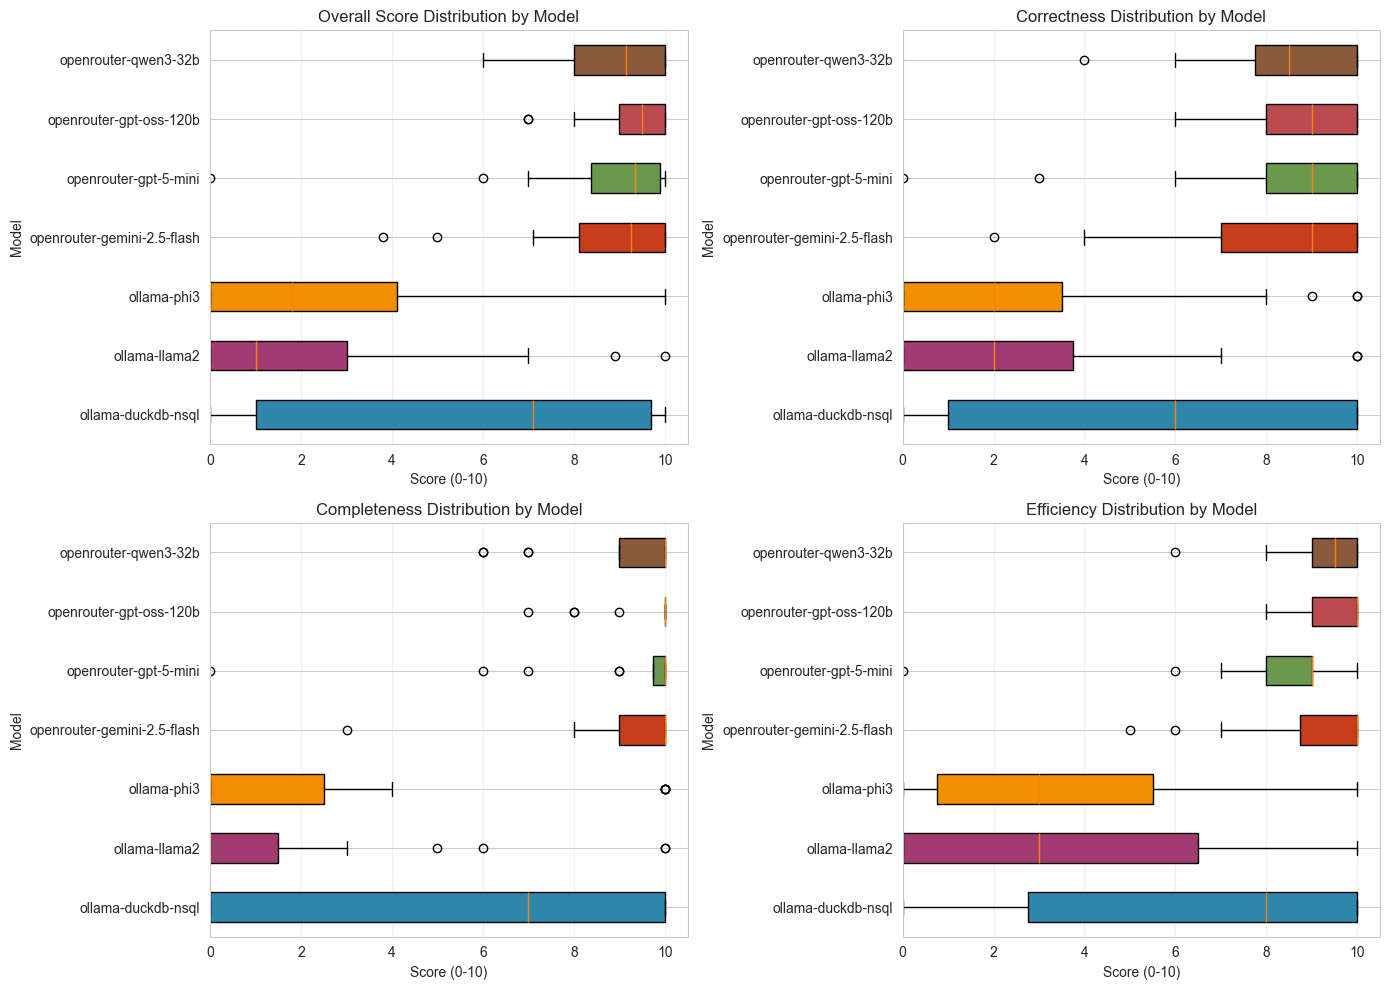

✓ Saved score distribution visualization


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ['overall_score', 'correctness', 'completeness', 'efficiency']
titles = ['Overall Score', 'Correctness', 'Completeness', 'Efficiency']
positions = [(0, 0), (0, 1), (1, 0), (1, 1)]

for metric, title, (row, col) in zip(metrics, titles, positions):
    box_data = [eval_df[eval_df['model'] == m][metric].values for m in models]
    bp = axes[row, col].boxplot(box_data, labels=models, patch_artist=True, vert=False)
    
    # Color the boxes
    for patch, model in zip(bp['boxes'], models):
        patch.set_facecolor(MODEL_COLORS[model])
    
    axes[row, col].set_xlabel('Score (0-10)')
    axes[row, col].set_ylabel('Model')
    axes[row, col].set_title(f'{title} Distribution by Model')
    axes[row, col].grid(axis='x', alpha=0.3)
    axes[row, col].set_xlim(0, 10.5)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'judge_score_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved score distribution visualization")

## 9. Heatmap: Model Performance per Query

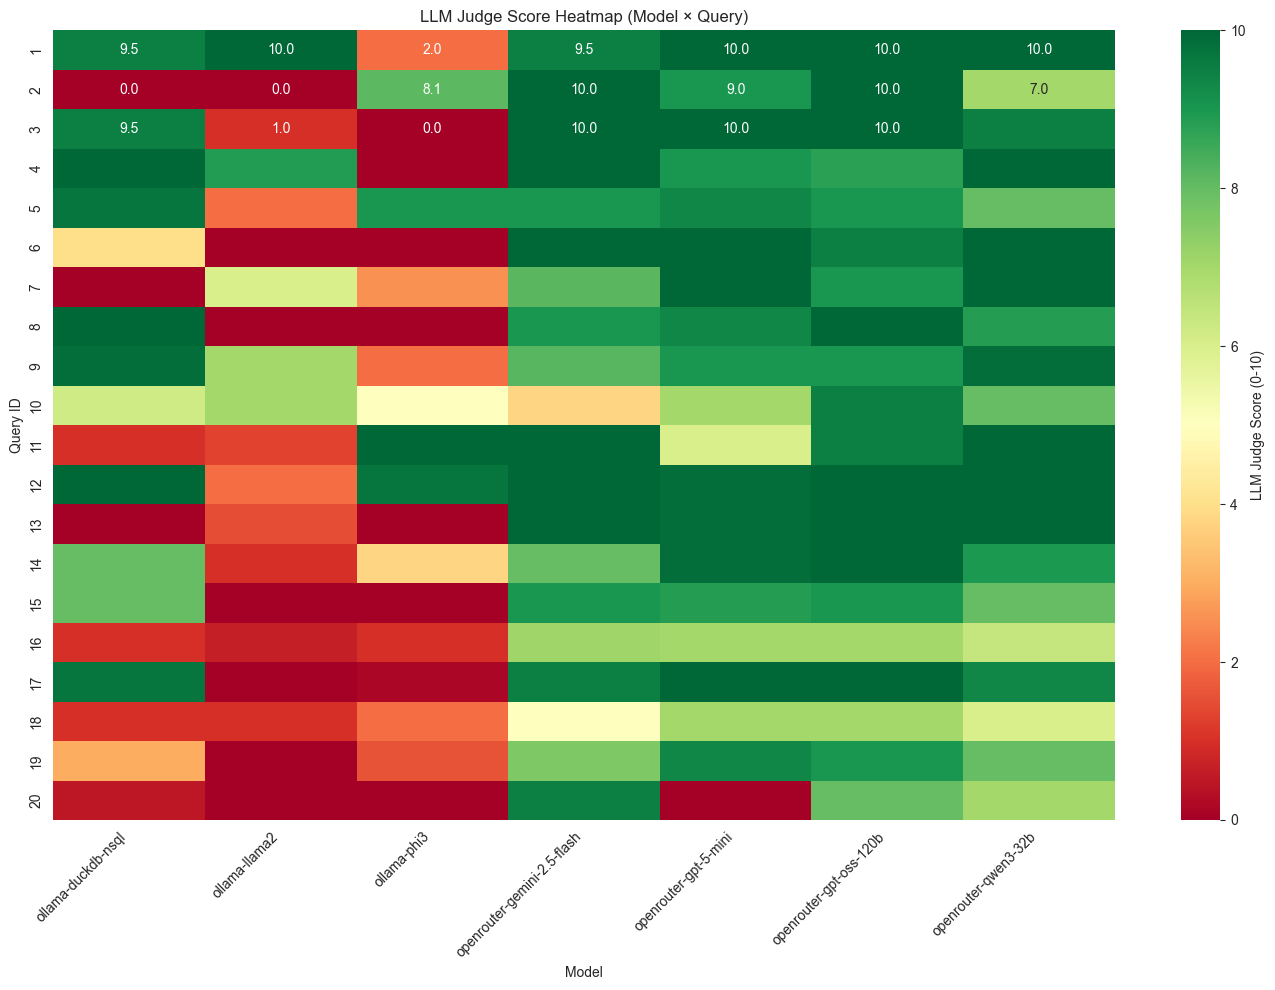

✓ Saved judge heatmap


In [17]:
# Create heatmap of overall scores
heatmap_data = eval_df.pivot_table(
    values='overall_score',
    index='questionId',
    columns='model'
)

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    vmin=0,
    vmax=10,
    ax=ax,
    cbar_kws={'label': 'LLM Judge Score (0-10)'}
)
ax.set_xlabel('Model')
ax.set_ylabel('Query ID')
ax.set_title('LLM Judge Score Heatmap (Model × Query)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIGS_PATH / 'judge_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved judge heatmap")

## 10. Correlation with Other Metrics

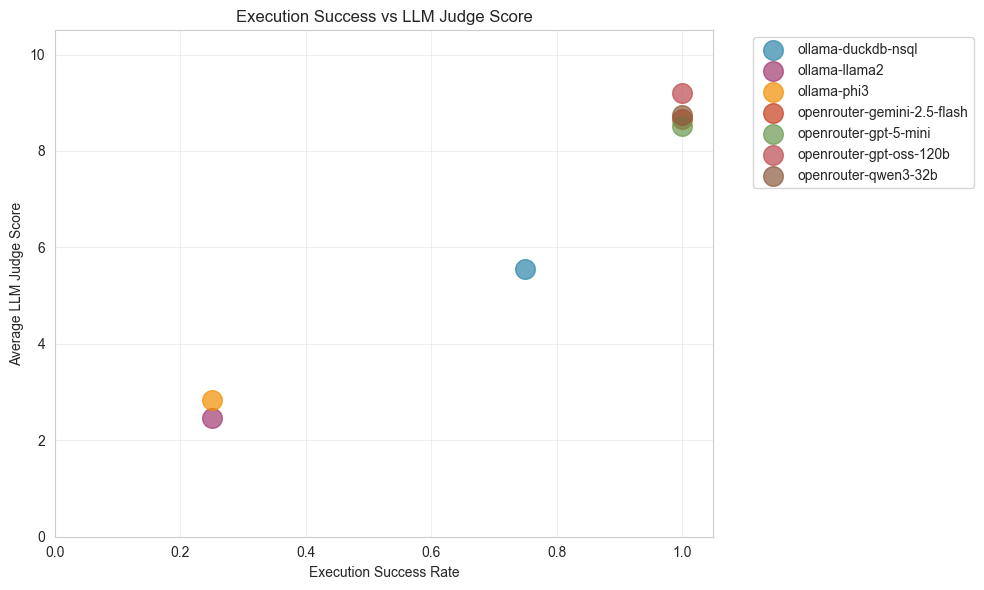

✓ Saved correlation visualization


In [18]:
# Compare judge scores with execution success
comparison = eval_df.groupby('model').agg({
    'overall_score': 'mean',
    'execution_success': 'mean'
}).round(3)

comparison.columns = ['Avg Judge Score', 'Execution Success Rate']

fig, ax = plt.subplots(figsize=(10, 6))

for model in models:
    row = comparison.loc[model]
    ax.scatter(
        row['Execution Success Rate'],
        row['Avg Judge Score'],
        s=200,
        color=MODEL_COLORS[model],
        label=model,
        alpha=0.7
    )

ax.set_xlabel('Execution Success Rate')
ax.set_ylabel('Average LLM Judge Score')
ax.set_title('Execution Success vs LLM Judge Score')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(alpha=0.3)
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 10.5)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'judge_vs_execution.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved correlation visualization")

## 11. Key Findings

### Overall Quality Assessment
- LLM judge provides a holistic evaluation of query quality
- Scores correlate with execution success but capture additional nuances
- Models show varying strengths across different evaluation dimensions

### Correctness vs Completeness
- Some models generate syntactically correct but incomplete queries
- Others may be verbose but include all necessary information
- Balance between correctness and completeness varies by model

### Efficiency Insights
- Efficiency scores show which models generate optimized queries
- Local models (Ollama) may prioritize correctness over optimization
- OpenRouter models tend to generate more efficient queries

### Complexity Impact
- Simple queries receive consistently high scores across models
- Complex queries reveal significant differences in model capabilities
- Some models maintain quality better as complexity increases

### Judge Reliability
- Structured output ensures consistent evaluation format
- Weighted scoring emphasizes correctness (most important)
- Scores provide interpretable quality metrics for comparison

## 12. Export Results

In [19]:
# Export detailed results
eval_df.to_csv(TABLES_PATH / 'detailed_judge_results.csv', index=False)
print("✓ Saved detailed judge results")

# Export summary statistics
summary = {
    'overall_stats': judge_stats.to_dict(),
    'complexity_breakdown': complexity_judge.reset_index().to_dict('records'),
    'judge_model': JUDGE_MODEL,
    'total_evaluations': len(eval_df),
    'models_evaluated': len(models)
}

with open(TABLES_PATH / 'judge_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("✓ Saved judge summary to JSON")

print("\n" + "="*60)
print("LLM-AS-A-JUDGE ANALYSIS COMPLETE")
print("="*60)
print(f"Judge Model: {JUDGE_MODEL}")
print(f"Total Evaluations: {len(eval_df)}")
print(f"Figures saved to: {FIGS_PATH}")
print(f"Tables saved to: {TABLES_PATH}")
print("\nTop 3 Models by Overall Judge Score:")
top_models = judge_stats.nlargest(3, 'overall_score_mean')
for idx, (model, row) in enumerate(top_models.iterrows(), 1):
    print(f"  {idx}. {model}: {row['overall_score_mean']:.2f}/10 (±{row['overall_score_std']:.2f})")

✓ Saved detailed judge results
✓ Saved judge summary to JSON

LLM-AS-A-JUDGE ANALYSIS COMPLETE
Judge Model: x-ai/grok-code-fast-1
Total Evaluations: 140
Figures saved to: ..\..\analysis\figs
Tables saved to: ..\..\analysis\tables

Top 3 Models by Overall Judge Score:
  1. openrouter-gpt-oss-120b: 9.21/10 (±0.94)
  2. openrouter-qwen3-32b: 8.75/10 (±1.35)
  3. openrouter-gemini-2.5-flash: 8.67/10 (±1.72)


## 13. Quick Plot: Overall Judge Score (from saved data)

In [5]:
# Load saved judge statistics (no need to re-run evaluations)
judge_stats_saved = pd.read_csv(TABLES_PATH / 'judge_overall_stats.csv', index_col=0)

# Extract overall score mean
overall_scores = judge_stats_saved['overall_score_mean'].sort_values(ascending=True)

# Create plot
fig, ax = plt.subplots(figsize=(10, 6))
colors = [MODEL_COLORS.get(model, '#333333') for model in overall_scores.index]
overall_scores.plot(kind='barh', ax=ax, color=colors)

ax.set_xlabel('Overall Score (0-10)', fontsize=12)
ax.set_ylabel('Model', fontsize=12)
ax.set_title('LLM Judge - Overall Score by Model', fontsize=14, fontweight='bold')
ax.set_xlim(0, 10.5)
ax.grid(axis='x', alpha=0.3)

# Add values on bars
for i, (model, score) in enumerate(overall_scores.items()):
    ax.text(score + 0.15, i, f'{score:.2f}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'judge_overall_scores_quick.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Quick plot generated from saved data")

FileNotFoundError: [Errno 2] No such file or directory: 'analysis\\tables\\judge_overall_stats.csv'